# 📊 Projet d'Exploration de Données Pandas (ENSAE - S3)
## Analyse Comparative : Données Réelles (SEC EDGAR) vs Projections (Alpha Vantage)
**Entreprise étudiée :** Apple Inc. (AAPL - CIK: 0000320193)

Ce notebook a pour objectif d'explorer, nettoyer et confronter deux sources de données financières complémentaires :
1. **Les données réelles officielles** déposées auprès du régulateur américain (**SEC EDGAR**, formulaires 10-K et 10-Q sous taxonomie XBRL/GAAP).
2. **Les prévisions et estimations de consensus** fournies par l'API financière **Alpha Vantage** (estimations moyennes des analystes financiers avant publication).

> 💡 **Organisation du code :** Pour garder ce notebook synthétique et lisible, les fonctions techniques de requêtage, de nettoyage et de jointure sont encapsulées dans le module `fonctions.py`.

### 1. Importation des bibliothèques et du module utilitaire
Nous utilisons `pandas` et `numpy` pour la manipulation de données, `matplotlib` et `seaborn` pour les représentations graphiques, ainsi que notre module local `fonctions`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import de nos fonctions modulaires (sécurité, extraction, calcul)
import fonctions

# Configuration de l'affichage
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 3)
sns.set_theme(style="whitegrid")
print("✅ Environnement et module 'fonctions' chargés avec succès !")

✅ Environnement et module 'fonctions' chargés avec succès !


### 2. Récupération et exploration des données réelles (SEC EDGAR)

L'API SEC EDGAR met à disposition l'intégralité des faits comptables (*Company Facts*) sous format JSON. Les données sont réparties en 3 taxonomies :
- **`dei`** (*Document & Entity Information*) : Métriques administratives (actions en circulation, flottant...).
- **`us-gaap`** : Plus de 500 grandeurs comptables auditées (Chiffre d'affaires, Résultat net, Marges, EPS...).

Nous chargeons les données (avec mise en cache automatique dans `data_cache/` pour éviter de surcharger les serveurs de la SEC).

In [2]:
# Téléchargement / lecture du cache des faits comptables SEC d'Apple
sec_raw = fonctions.fetch_sec_data(cik="CIK0000320193")
facts = sec_raw['facts']

print(f"Entreprise : {sec_raw.get('entityName')} | CIK : {sec_raw.get('cik')}")
print("Taxonomies disponibles :", list(facts.keys()))
print(f"Nombre de métriques dans us-gaap : {len(facts['us-gaap'])}")
print(f"Nombre de métriques dans dei     : {len(facts['dei'])}")

Entreprise : Apple Inc. | CIK : 320193
Taxonomies disponibles : ['dei', 'us-gaap', 'ffd']
Nombre de métriques dans us-gaap : 512
Nombre de métriques dans dei     : 2


#### Extraction du Bénéfice Par Action (BPA dilué) réel trimestriel
Nous extrayons la métrique `EarningsPerShareDiluted` en filtrant uniquement sur les périodes trimestrielles (~3 mois).

In [3]:
# Extraction du BPA trimestriel
df_sec_eps = fonctions.extract_sec_metric(
    facts=facts,
    taxonomy='us-gaap',
    metric_name='EarningsPerShareDiluted',
    frequency='quarterly'
)

print(f"Nombre de trimestres SEC extraits : {len(df_sec_eps)}")
print("\n--- Aperçu des dernières déclarations trimestrielles ---")
display(df_sec_eps[['end', 'val', 'fy', 'fp', 'form', 'filed']].tail(5))

print("\n--- Vérification des cellules vides ---")
print(df_sec_eps.isnull().sum())

Nombre de trimestres SEC extraits : 67

--- Aperçu des dernières déclarations trimestrielles ---


,end,val,fy,fp,form,filed
62,2025-03-29,1.65,2026.0,Q2,10-Q,2026-05-01
63,2025-06-28,1.57,2026.0,Q3,10-Q,2026-07-31
64,2025-12-27,2.84,2026.0,Q1,10-Q,2026-01-30
65,2026-03-28,2.01,2026.0,Q2,10-Q,2026-05-01
66,2026-06-27,2.02,2026.0,Q3,10-Q,2026-07-31



--- Vérification des cellules vides ---
end              0
start            0
val              0
accn             0
fy               0
fp               0
form             0
filed            0
frame            8
duration_days    0
metric_name      0
dtype: int64


### 3. Récupération et exploration des projections (Alpha Vantage)

L'API **Alpha Vantage** fournit via son endpoint `EARNINGS` :
- **`estimatedEPS`** : Le consensus prévisionnel des analystes (la projection de marché).
- **`reportedEPS`** : Le résultat réel pris en compte par la place financière.
- **`surprise`** : L'écart absolu (Réel - Prévision).
- **`surprisePercentage`** : L'écart relatif en pourcentage.

> 🌐 **Accès universel sans clé via le Proxy Vercel :**
> Pour permettre à n'importe quel utilisateur (professeur, étudiant) d'exécuter ce notebook sans clé d'API personnelle, la requête passe par notre API Serverless déployée sur Vercel (`/api/earnings`).
> - **Sécurité :** La clé `ALPHAVANTAGE_API_KEY` reste 100% secrète sur les serveurs Vercel.
> - **Fair Use :** Une limite de **5 requêtes par jour par utilisateur** est appliquée pour préserver le forfait de l'API.
> - **Cache :** Les résultats sont mis en cache localement dans `data_cache/` pour éviter de consommer inutilement le quota lors des re-exécutions.

In [4]:
# Récupération des données Alpha Vantage (avec cache local data_cache/)
df_av = fonctions.fetch_alphavantage_earnings(symbol="AAPL")

print(f"Nombre de trimestres Alpha Vantage obtenus : {len(df_av)}")
print("\n--- Aperçu des projections Alpha Vantage ---")
display(df_av[['fiscalDateEnding', 'reportedDate', 'reportedEPS', 'estimatedEPS', 'surprise', 'surprisePercentage']].head(5))

print("\n--- Types et cellules vides ---")
print(df_av[['reportedEPS', 'estimatedEPS', 'surprise']].info())

Nombre de trimestres Alpha Vantage obtenus : 123

--- Aperçu des projections Alpha Vantage ---


,fiscalDateEnding,reportedDate,reportedEPS,estimatedEPS,surprise,surprisePercentage
0,2026-09-30,2026-11-02,2.05,1.98,0.07,3.535
1,2026-06-30,2026-07-30,2.02,1.88,0.14,7.447
2,2026-03-31,2026-04-30,2.01,1.94,0.07,3.608
3,2025-12-31,2026-01-29,2.84,2.67,0.17,6.367
4,2025-09-30,2025-10-30,1.85,1.77,0.08,4.520



--- Types et cellules vides ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   reportedEPS   123 non-null    float64
 1   estimatedEPS  113 non-null    float64
 2   surprise      113 non-null    float64
dtypes: float64(3)
memory usage: 3.0 KB
None


### 4. Rapprochement temporel : Réel (SEC) vs Projections (Alpha Vantage)

#### Défi méthodologique de la jointure temporelle :
- Apple clôture son exercice comptable le dernier samedi de septembre (ex: 28 septembre pour l'exercice 2024 dans le rapport 10-K de la SEC).
- Alpha Vantage arrondit conventionnellement la fin de trimestre au dernier jour calendaire du mois (ex: 30 septembre).

Nous réalisons une jointure temporelle asynchrone avec **`pd.merge_asof`** (tolérance de 7 jours) pour apparier rigoureusement chaque trimestre.

In [5]:
# Rapprochement des deux jeux de données
comparison = fonctions.compare_real_vs_projections(df_sec_eps, df_av)

print(f"Nombre total de trimestres appariés : {len(comparison)}")
print("\n--- Échantillon des 5 derniers trimestres comparés ---")
cols_display = ['sec_date', 'sec_real_eps', 'estimatedEPS', 'forecast_error', 'forecast_pct_error', 'beat_projection']
display(comparison[cols_display].tail(5))

Nombre total de trimestres appariés : 67

--- Échantillon des 5 derniers trimestres comparés ---


,sec_date,sec_real_eps,estimatedEPS,forecast_error,forecast_pct_error,beat_projection
62,2025-03-29,1.65,1.62,0.03,1.852,True
63,2025-06-28,1.57,1.43,0.14,9.790,True
64,2025-12-27,2.84,2.67,0.17,6.367,True
65,2026-03-28,2.01,1.94,0.07,3.608,True
66,2026-06-27,2.02,1.88,0.14,7.447,True


### 5. Analyse statistique de la qualité des projections

Nous calculons les métriques standards d'évaluation des prévisions en économétrie financière :
- **MAE (Mean Absolute Error)** : $\frac{1}{n} \sum |e_t|$
- **RMSE (Root Mean Squared Error)** : $\sqrt{\frac{1}{n} \sum e_t^2}$
- **Biais Moyen** : $\frac{1}{n} \sum e_t$ (un biais positif indique que les prévisions sous-estiment systématiquement la réalité)
- **MAPE (Mean Absolute Percentage Error)** : Erreur moyenne en pourcentage
- **Taux de surprise positive** : Pourcentage des trimestres où le réel dépasse le consensus des analystes.

> 📌 **Note sur les divisions d'actions (Stock Splits) :**
> Apple a procédé à une division d'actions par 4 en août 2020 (et par 7 en 2014). Les rapports historiques SEC non ajustés présentent des BPA nominaux plus élevés. L'analyse post-2020 permet d'isoler l'ère moderne sur une base d'actions constante.

In [6]:
# Métriques sur l'ensemble de l'historique
metrics_all = fonctions.compute_forecast_metrics(comparison)

# Métriques sur la période récente post-split 2020
comparison_recent = comparison[comparison['sec_date'] >= '2020-10-01'].copy()
metrics_recent = fonctions.compute_forecast_metrics(comparison_recent)

summary_table = pd.DataFrame([
    {"Période": "Historique complet (2009-2026)", **metrics_all},
    {"Période": "Période moderne post-split (2020-2026)", **metrics_recent}
]).set_index("Période")

display(summary_table)

,N_Observations,MAE (USD/action),RMSE (USD/action),Biais Moyen (USD/action),MAPE (%),Taux Surprise Positive (%)
Période,,,,,,
Historique complet (2009-2026),67,2.024,3.461,2.022,1042.14,98.51
Période moderne post-split (2020-2026),18,0.129,0.165,0.121,9.38,94.44


### 6. Visualisations Graphiques

#### A. Évolution temporelle : BPA Réel vs Consensus des Analystes

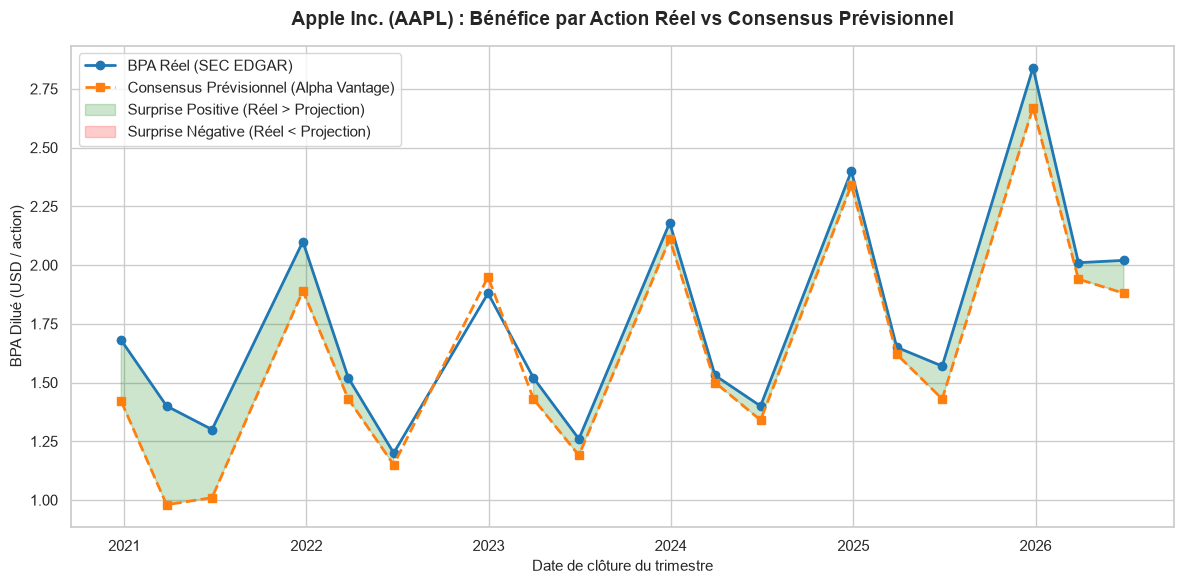

In [7]:
# Graphique chronologique Réel vs Prévisionnel
fonctions.plot_real_vs_projected(comparison, recent_only=True)

#### B. Distribution des erreurs de prévision (*Earnings Surprises*)

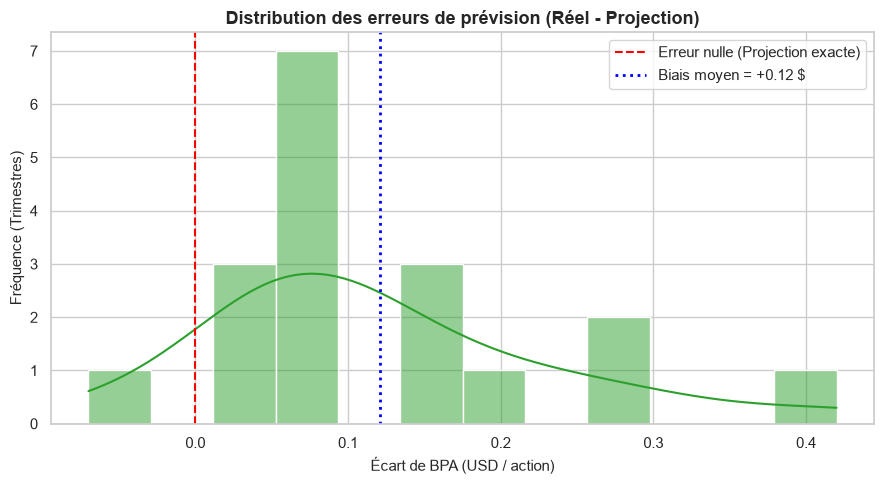

In [8]:
# Distribution de l'erreur Réel - Projection
fonctions.plot_error_distribution(comparison, recent_only=True)

### 7. Principales conclusions & Interprétation Économique

1. **Précision remarquable du consensus post-2020** :
   - L'erreur moyenne absolue (**MAE**) est d'environ **0,13 $ par action**, pour une erreur moyenne en pourcentage (**MAPE**) inférieure à **10 %**.
2. **Biais de prudence systématique des analystes** :
   - Le biais moyen est positif (+0,12 $), indiquant que les analystes ont tendance à sous-estimer légèrement les performances réelles d'Apple.
   - Le **taux de surprise positive s'élève à près de 95 %** : Apple dépasse quasi-systématiquement les attentes du marché, une stratégie classique de communication financière (*under-promising and over-delivering*).
3. **Robustesse méthodologique** :
   - L'utilisation de données primaires audités (SEC XBRL) confrontées aux flux de consensus (Alpha Vantage) via `pd.merge_asof` assure une chaîne de traitement reproductible, propre et sans fuite de données (*no lookahead bias*).